# From ABC to BayesFlow
_Author: Jonas Arruda_

We infer a reaction rate from stochastic chemical kinetics using ABC, then reuse the same simulator and prior in BayesFlow.

ABC fits one observed dataset at a time. It compares simulations with observations using a distance function. BayesFlow trains an estimator across the prior, so the trained estimator can analyze additional datasets without retraining. An adapter maps the simulator output to inference variables and conditions.

This example follows the [pyABC chemical reaction tutorial](https://pyabc.readthedocs.io/en/latest/examples/chemical_reaction.html). Install [pyABC](https://github.com/icb-dcm/pyabc) to run the first part. Readers familiar with ABC can skip to the BayesFlow workflow.

In [1]:
# Run once if needed: %pip install pyabc

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tempfile
from pathlib import Path

plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#216869", "#C17C54", "#77618D", "#587A9C"])

In [3]:
from pyabc import RV, Distribution, ABCSMC, weighted_statistics
from pyabc.sampler import SingleCoreSampler
from pyabc.visualization import plot_kde_1d, plot_sample_numbers

### Simulator

We consider a Markov jump process model $m_1$ for conversion of (chemical) species $X$ to species $Y$:

$$
   X + Y \xrightarrow{k} 2Y.
$$

The model is equipped with a single rate parameter $k$. To simulate this model, we define a simple Gillespie simulator:

In [4]:
def helper(x, pre, c):
    return (x**pre).prod(1) * c


def gillespie(x, c, pre, post, max_t):
    """
    Gillespie forward simulation.

    Parameters
    ----------
    x: 1D array of size n_species
        The initial numbers.
    c: 1D array of size n_reactions
        The reaction rates.
    pre: array of size n_reactions x n_species
        What is to be consumed.
    post: array of size n_reactions x n_species
        What is to be produced
    max_t: int
        Simulate up to time max_t

    Returns
    -------
    t, X: 1d array, 2d array, with t: The time points. X: The history 
        of the species. ``X.shape == (t.size, x.size)``
    """
    t = 0
    t_store = [t]
    x_store = [x.copy()]
    S = post - pre

    while t < max_t:
        h_vec = helper(x, pre, c)
        h0 = h_vec.sum()
        if h0 == 0:
            break
        delta_t = np.random.exponential(1 / h0)
        # no reaction can occur any more
        if not np.isfinite(delta_t):
            t_store.append(max_t)
            x_store.append(x)
            break
        reaction = np.random.choice(c.size, p=h_vec / h0)
        t = t + delta_t
        x = x + S[reaction]

        t_store.append(t)
        x_store.append(x)

    return np.array(t_store), np.array(x_store)

Next, we define the model in terms of the initial molecule numbers $x_0$, an array ``pre`` which determines what is to be consumed (the LHS of the reaction equations) and an array ``post`` which determines what is to be produced (the RHS of the reaction equations). Further, we define that the simulation time should not exceed ``MAX_T`` seconds.

The simulation starts with initial concentrations $X=40$ and $Y=3$.
The reaction $X + Y \rightarrow 2Y$ is encoded in ``pre = [[1, 1]]`` and ``post = [[0, 2]]``.

In [5]:
MAX_T = 0.1

class StochasticModel:
    __name__ = "StochasticModel"
    x0 = np.array([40, 3])  # Initial molecule numbers
    pre = np.array([[1, 1]], dtype=int)
    post = np.array([[0, 2]])

    def __call__(self, par):
        rate = np.array([np.power(10, par["rate"])])
        t, X = gillespie(
            self.x0, rate, self.pre, self.post, MAX_T
        )
        return {"t": t, "X": X}

Below, we draw one stochastic simulation from the model (the ``Observation``) and visualize it:

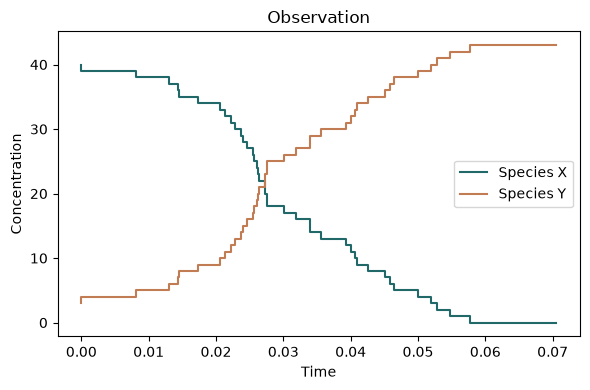

In [6]:
true_rate = np.log10(2.3)
observations = StochasticModel()({"rate": true_rate})
fig, axes = plt.subplots(ncols=1, tight_layout=True, figsize=(6, 4))
axes.step(observations["t"], observations["X"])
axes.legend(["Species X", "Species Y"])
axes.set_xlabel("Time")
axes.set_ylabel("Concentration")
axes.set_title("Observation")
plt.show()

We observe that species $X$ is converted into species $Y$.

In `pyABC`, we need to define a distance function as $L_1$ norm of two trajectories, evaluated at 20 time points. This is not needed for `BayesFlow`.

$$
  \mathrm{distance}(X_1, X_2) =
     \frac{1}{N}\sum_{n=1}^{N} 
           \left  |X_1(t_n) -X_2(t_n) 
           \right|, \quad t_n = \frac{n}{N}T, \quad  N=20 \,.
$$

We only consider the concentration of species $Y$ in the distance calculation and not every time point which we simulate is actually observed. In code, this translates to:

In [7]:
N_TEST_TIMES = 20
t_test_times = np.linspace(0, MAX_T, N_TEST_TIMES)

def distance(x, y):
    xt_ind = np.searchsorted(x["t"], t_test_times, side="right") - 1
    yt_ind = np.searchsorted(y["t"], t_test_times, side="right") - 1
    error = (
        np.absolute(x["X"][:, 1][xt_ind] - y["X"][:, 1][yt_ind]).sum()
        / t_test_times.size
    )
    return error

We choose a uniform prior over the interval $[-1, 1]$ in $\log_{10}$ space for the single rate parameter. The two numbers passed to `RV("uniform", ...)` are the lower bound and interval width:

In [8]:
prior = Distribution(rate=RV("uniform", -1, 2))

We initialize `ABCSMC` with the same model, prior, and distance function. We use 200 particles per population and a single-core sampler to keep the example easy to run in a notebook. The observed data are the trajectory generated above.

In [9]:
abc = ABCSMC(
    models=StochasticModel(),
    parameter_priors=prior,
    distance_function=distance,
    population_size=200,
    sampler=SingleCoreSampler(),
)

db_dir = tempfile.TemporaryDirectory()
abc.new("sqlite:///" + str(Path(db_dir.name) / "mjp.db"), observations);

ABC.History INFO: Start <ABCSMC id=1, start_time=2026-10-23 12:57:13>


In [10]:
abc_history = abc.run(minimum_epsilon=1.0, max_nr_populations=10)

ABC INFO: Calibration sample t = -1.
ABC INFO: t: 0, eps: 1.47500000e+01.
ABC INFO: Accepted: 200 / 384 = 5.2083e-01, ESS: 2.0000e+02.
ABC INFO: Timing t=0 [s]: total=0.207, simulation=0.138 (67%), pipeline-setup=0.00239, prepare-next=0.0145 (population-size=0.0062, distance=0.00108).
ABC INFO: t: 1, eps: 6.62500000e+00.
ABC INFO: Accepted: 200 / 372 = 5.3763e-01, ESS: 1.9701e+02.
ABC INFO: Timing t=1 [s]: total=0.385, simulation=0.257 (67%), pipeline-setup=0.00208, prepare-next=0.0146 (population-size=0.00647, distance=0.00129).
ABC INFO: t: 2, eps: 3.85000000e+00.
ABC INFO: Accepted: 200 / 479 = 4.1754e-01, ESS: 1.9704e+02.
ABC INFO: Timing t=2 [s]: total=0.38, simulation=0.315 (83%), pipeline-setup=0.00226, prepare-next=0.0137 (population-size=0.0062, distance=0.00123).
ABC INFO: t: 3, eps: 2.29645163e+00.
ABC INFO: Accepted: 200 / 619 = 3.2310e-01, ESS: 1.8488e+02.
ABC INFO: Timing t=3 [s]: total=0.444, simulation=0.392 (88%), pipeline-setup=0.00191, prepare-next=0.0132 (population

We then inspect the distribution of the rate parameter:

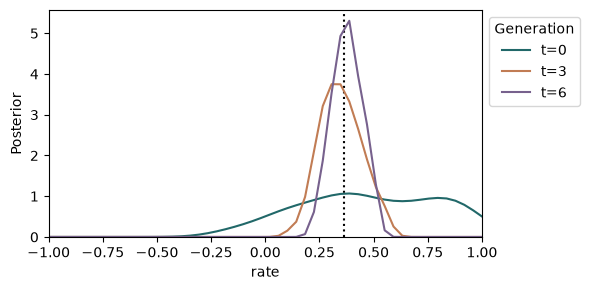

In [11]:
fig, axes = plt.subplots(1, tight_layout=True)
fig.set_size_inches((6, 3))
axes.axvline(true_rate, color="black", linestyle="dotted")
for t in range(0, abc_history.n_populations, 3):
    df, w = abc_history.get_distribution(m=0, t=t)
    plot_kde_1d(
        df,
        w,
        "rate",
        xmin=-1, xmax=1,
        ax=axes,
        label=f"t={t}",
    )
axes.legend(title="Generation", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

We can see that the posterior distribution is centered around the true rate parameter value. So the ABC run was successful for this single dataset.

## Transitioning to BayesFlow

We let BayesFlow select the backend automatically.

In [12]:
import bayesflow as bf

INFO:bayesflow:Multiple Keras-compatible backends detected (JAX, PyTorch, TensorFlow). Defaulting to JAX.
To override, set the KERAS_BACKEND environment variable before importing bayesflow.
See: https://keras.io/getting_started/#configuring-your-backend
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:bayesflow:Using backend 'jax'


We reuse the same prior and simulator in BayesFlow. The 20 observations of species $Y$ become the inference conditions. In pyABC, we selected these observations inside the distance function.

In [13]:
sim = StochasticModel()

In [14]:
def prior_helper():
    """The ABC prior returns a Parameter Object from pyabc which we convert to a dict."""
    return dict(rate=prior.rvs()["rate"])

def sim_helper(rate):
    """The simulator returns a dict, we extract the output at the test times."""
    temp = sim({"rate": rate})
    xt_ind = np.searchsorted(temp["t"], t_test_times, side="right") - 1
    obs = temp["X"][:, 1][xt_ind]
    return dict(obs=obs)

In [15]:
# We create a simulator from the helper functions
simulator = bf.make_simulator([prior_helper, sim_helper])

The workflow builds an adapter from `inference_variables` and `inference_conditions`. Here, the observations are already a small vector, so we do not need a summary network.

In [16]:
num_simulations = 2 ** 14
training_data = simulator.sample(num_simulations)
epochs = 100
batch_size = 64

We use a `StableConsistencyModel` as the inference network. The workflow standardizes both the rate parameter and the observations during training.

In [17]:
workflow = bf.BasicWorkflow(
    simulator=simulator,
    inference_variables="rate",
    inference_conditions="obs",
    inference_network=bf.networks.StableConsistencyModel(
        subnet_kwargs={"widths": (128,)*3},
    ),
    standardize="all",
    initial_learning_rate=1e-3
)

Offline training reuses the same 16,384 simulations for 100 epochs. We simulate a separate set of 256 datasets for validation. The trained estimator can then infer the rate for many datasets without retraining.

In [18]:
history = workflow.fit_offline(
    data=training_data,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=256,
    verbose=2,
)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/100
256/256 - 4s - 14ms/step - loss: 0.8308 - val_loss: 0.8413
Epoch 2/100
256/256 - 0s - 774us/step - loss: 0.7449 - val_loss: 0.5168
Epoch 3/100
256/256 - 0s - 816us/step - loss: 0.2574 - val_loss: 0.1331
Epoch 4/100
256/256 - 0s - 768us/step - loss: 0.1599 - val_loss: 0.4147
Epoch 5/100
256/256 - 0s - 758us/step - loss: 0.1748 - val_loss: -1.1376e-02
Epoch 6/100
256/256 - 0s - 767us/step - loss: 0.2091 - val_loss: 0.1164
Epoch 7/100
256/256 - 0s - 757us/step - loss: 0.1796 - val_loss: 0.4111
Epoch 8/100
256/256 - 0s - 757us/step - loss: 0.1125 - val_loss: 0.1505
Epoch 9/100
256/256 - 0s - 775us/step - loss: 0.1318 - val_loss: 0.2210
Epoch 10/100
256/256 - 0s - 797us/step - loss: 0.1733 - val_loss: 0.1654
Epoch 11/100
256/256 - 0s - 924us/step - loss: 0.1213 - val_loss: 0.2711
Epoch 12/100
256/256 - 0s - 780us/step - loss: 0.1382 - val_loss: 0.1252
Epoch 13/100
256/256 - 0s - 857us/step - loss: 0.0519 - val_loss: -1.3193e-01
Epoch 14/100
256/256 - 0s - 913us/step - loss: 0.08

INFO:bayesflow:Training completed in 25.96 seconds.


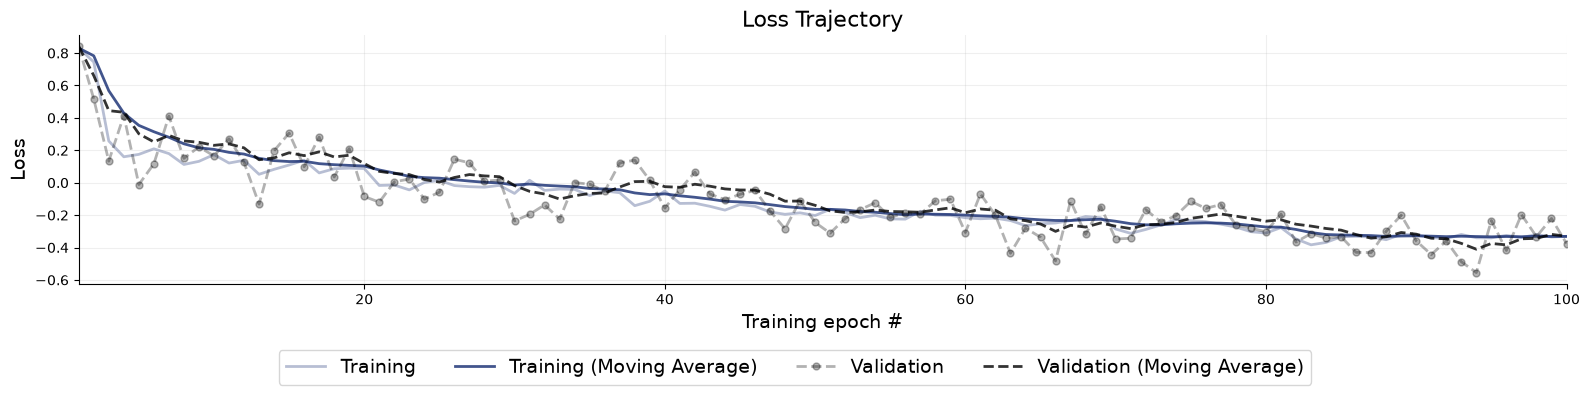

In [19]:
f = bf.diagnostics.loss(history)

## Validation Phase

Check parameter recovery and simulation-based calibration on simulations not used for training. These diagnostics are inexpensive after amortized training. With ABC, we would need a separate fit for each validation dataset.

In [20]:
# Set the number of posterior draws you want to get
num_samples = 1000

# Simulate 300 scenarios and extract simulations and ground truth parameters
test_sims = workflow.simulate(300)
test_sims_params = {k: v for k, v in test_sims.items() if k in prior.keys()}
test_sims_data = {k: v for k, v in test_sims.items() if k not in prior.keys()}

# Obtain 1000 samples
samples = workflow.sample(conditions=test_sims_data, num_samples=num_samples)

INFO:bayesflow:Sampling completed in 5.71 seconds.


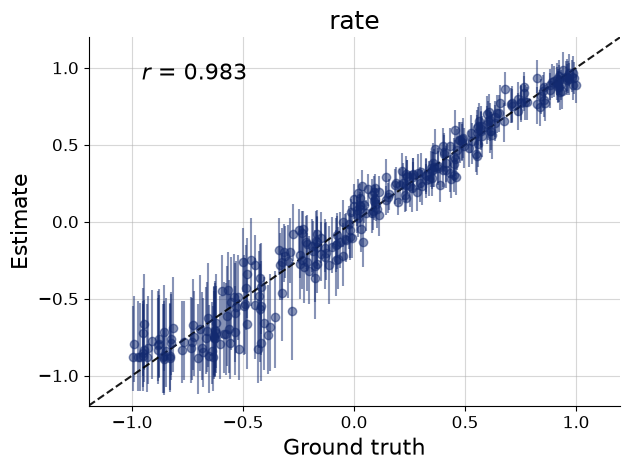

In [21]:
f = bf.diagnostics.recovery(samples, test_sims_params)

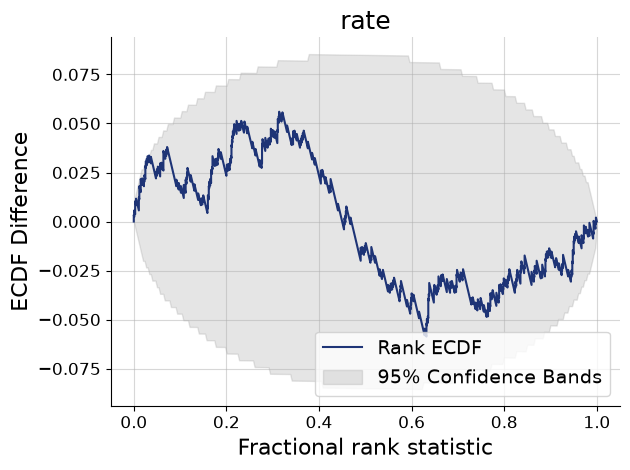

In [22]:
f = bf.diagnostics.calibration_ecdf(samples, test_sims_params, difference=True)

## Inference Phase

We now compare the BayesFlow and ABC posteriors for the observed trajectory. Both are approximations: ABC depends on its distance tolerance, and BayesFlow depends on training. Agreement between them is useful, but it does not replace the recovery and calibration checks above.

In [23]:
# We bring the observation into the right format
xt_ind = np.searchsorted(observations["t"], t_test_times, side="right") - 1
obs = observations["X"][:, 1][xt_ind]

# Obtain 1000 posterior samples
samples = workflow.sample(conditions={"obs": obs[None, :]}, num_samples=num_samples)

INFO:bayesflow:Sampling completed in 3.96 seconds.


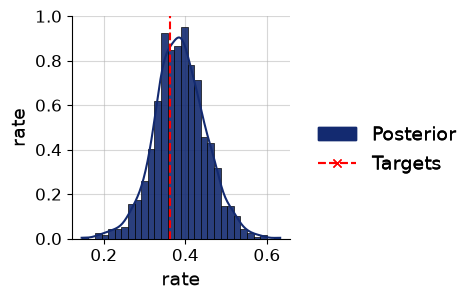

In [24]:
f = bf.diagnostics.pairs_posterior(samples, targets=np.array([true_rate]))

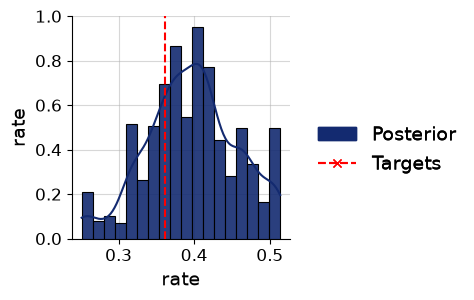

In [25]:
# abc gives us weighted samples, we resample them to get comparable samples
df, w = abc_history.get_distribution()
abc_samples = weighted_statistics.resample(df["rate"].values, w, 1000)

f = bf.diagnostics.pairs_posterior({"rate": abc_samples}, targets=np.array([true_rate]))

Compare the simulation budgets below. BayesFlow uses 16,384 training simulations, plus 256 for validation and 300 for the diagnostics above. Repeating training epochs adds no simulations. ABC fits this one dataset, while BayesFlow's training cost is shared across every dataset we analyze with the trained estimator.

BayesFlow training simulations: 16384
Number of simulations in ABC: 11543


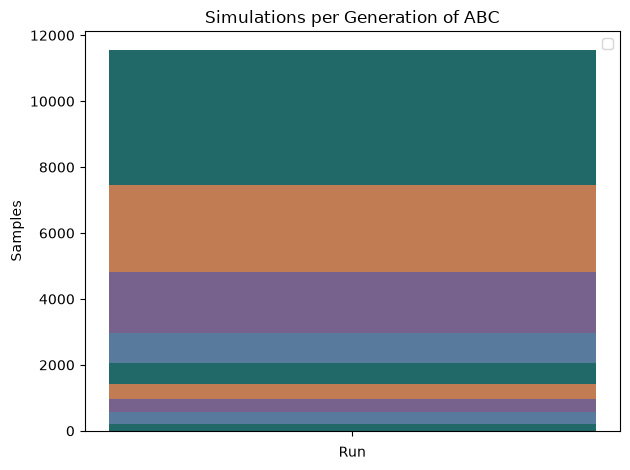

In [26]:
print(f"BayesFlow training simulations: {num_simulations}")
print(f"Number of simulations in ABC: {abc_history.total_nr_simulations}")

ax = plot_sample_numbers(abc_history)
ax.legend([])
ax.set_title("Simulations per Generation of ABC")
plt.show()

For higher-dimensional observations, we can train a summary network jointly with the inference network. The same workflow then learns both how to summarize the data and how to infer the parameters.